# KIRBOT – Asistente Virtual Especializado en Restaurantes (v2 · VS Code)
Versión del cuaderno original adaptada para **ejecutarse localmente en Visual Studio Code** (sin Colab) y con un
asistente más inteligente. La lógica vive en el paquete `kirbot/`; este cuaderno la usa paso a paso.

**Cómo ejecutarlo en VS Code**
1. Abre la carpeta del proyecto (`File ▸ Open Folder…`) e instala las extensiones recomendadas (Python y Jupyter).
2. Crea el entorno: `python -m venv .venv` y actívalo; luego `pip install -r requirements.txt`.
3. Abre este archivo, elige el kernel `.venv` (arriba a la derecha) y ejecuta las celdas en orden.

**Las 6 categorías:** `recomendacion_comidas`, `consulta_menu`, `gestion_pedidos`, `consulta_pedidos`,
`atencion_cliente` y `fuera_de_tema` (210 ejemplos, 35 por categoría, en `data/ejemplos.csv`).

> Tip: el Transformer (PASO 6) tarda unos minutos en CPU. Para iterar rápido deja `ENTRENAR_TRANSFORMER = False`;
> KIRBOT usará el clasificador TF-IDF de respaldo + la capa de reglas.

## PASO 1 – Instalar dependencias (solo la primera vez)

In [1]:
# Descomenta la siguiente línea si aún no instalaste los requisitos en el entorno del kernel:
# %pip install -q -r requirements.txt

## PASO 2 – Preparar el entorno
Semillas, ruta del proyecto y verificación de hardware (GPU/CPU).

In [2]:
import os, sys, random, warnings
from pathlib import Path
%pip install -q numpy pandas
import numpy as np
import pandas as pd

# Ubica la raíz del proyecto (donde está la carpeta kirbot/) aunque el cuaderno se abra desde otro sitio
RAIZ = Path.cwd()
while not (RAIZ / "kirbot").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

from kirbot.config import SEED
random.seed(SEED); np.random.seed(SEED)
os.environ["WANDB_DISABLED"] = "true"
warnings.filterwarnings("ignore")

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("Dispositivo:", "GPU " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (entrenamiento más lento)")
except ImportError:
    print("PyTorch no está instalado: podrás usar el modo TF-IDF (el Transformer requiere torch).")
print("Proyecto:", RAIZ)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
PyTorch no está instalado: podrás usar el modo TF-IDF (el Transformer requiere torch).
Proyecto: c:\Users\esteb\OneDrive\Desktop\KIRBOT\KIRBOT


## PASO 3 – Cargar el conjunto de datos (210 ejemplos)
El dataset está en `data/ejemplos.csv` (columnas `texto` y `categoria`). Puedes editarlo o agregar tus propios ejemplos.


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
DATOS CARGADOS: 210


,texto,categoria
30,Qué tipo de queso usan en las pizzas,consulta_menu
172,me pueden decir el estado del pedido número 105,consulta_pedidos
84,Quiero poner una queja sobre mi servicio,atencion_cliente
199,traduce esta frase al inglés,fuera_de_tema
60,Quiero saber el estado de mi pedido,consulta_pedidos
155,quita las papas de mi orden,gestion_pedidos
45,Quiero cambiar la cantidad de mi orden a dos h...,gestion_pedidos
182,reciben nequi,atencion_cliente


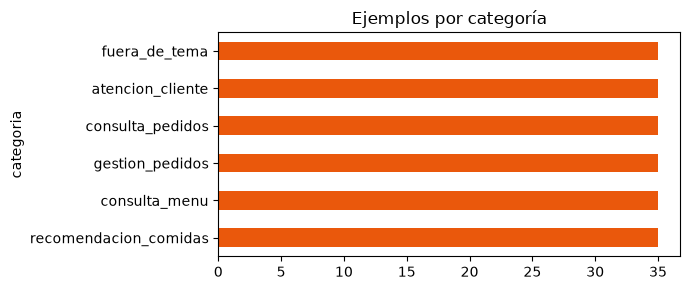

In [3]:
%pip install -q matplotlib
import matplotlib.pyplot as plt
%pip install -q scikit-learn
from kirbot.datos import cargar_dataset, dividir

df = cargar_dataset()          # limpia, normaliza y elimina duplicados
print("DATOS CARGADOS:", len(df))
display(df.sample(8, random_state=SEED))
df["categoria"].value_counts().sort_values().plot.barh(figsize=(7, 3), title="Ejemplos por categoría", color="#ea580c")
plt.tight_layout(); plt.show()

## PASO 4 – Dividir los datos
División estratificada: entrenamiento / validación / prueba (esta última **solo** se usa al final).

In [4]:
train_df, val_df, test_df, labels = dividir(df)
print("Entrenamiento:", len(train_df), "| Validación:", len(val_df), "| Prueba:", len(test_df))
print("Categorías:", labels)

Entrenamiento: 145 | Validación: 33 | Prueba: 32
Categorías: ['atencion_cliente', 'consulta_menu', 'consulta_pedidos', 'fuera_de_tema', 'gestion_pedidos', 'recomendacion_comidas']


## PASO 5 – Línea base rápida (TF-IDF + regresión logística)
Sirve de punto de comparación y de respaldo si no hay GPU.

== TF-IDF · prueba | accuracy = 0.688 ==
                       precision    recall  f1-score   support

     atencion_cliente       0.75      0.60      0.67         5
        consulta_menu       0.67      0.80      0.73         5
     consulta_pedidos       0.67      0.80      0.73         5
        fuera_de_tema       0.75      0.50      0.60         6
      gestion_pedidos       1.00      0.50      0.67         6
recomendacion_comidas       0.56      1.00      0.71         5

             accuracy                           0.69        32
            macro avg       0.73      0.70      0.68        32
         weighted avg       0.74      0.69      0.68        32



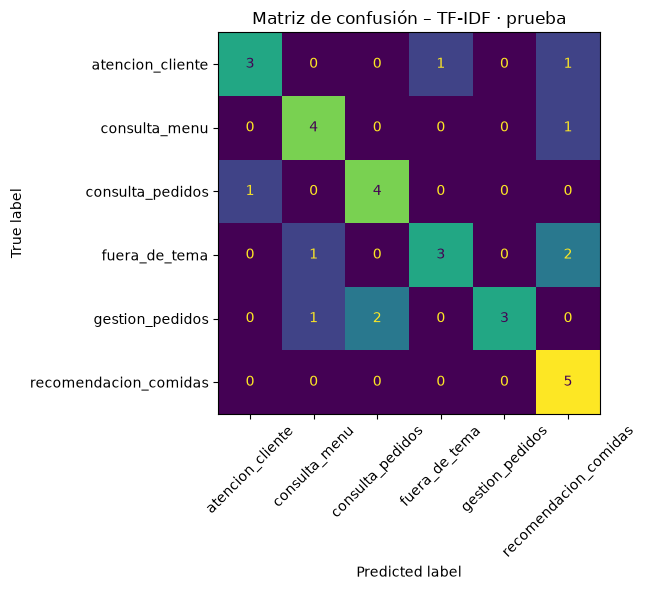

,texto,categoria,prediccion
2,Cuántos planetas tiene nuestro sistema solar,fuera_de_tema,consulta_menu
15,cuándo hay promociones,atencion_cliente,recomendacion_comidas
16,a qué hora cierran,atencion_cliente,fuera_de_tema
17,Cómo puedo consultar mi número de orden,consulta_pedidos,atencion_cliente
20,Qué lleva el perro caliente especial,consulta_menu,recomendacion_comidas
21,Recomiéndame una película de ciencia ficción,fuera_de_tema,recomendacion_comidas
23,cuánto llevo en el carrito,gestion_pedidos,consulta_pedidos
25,añade tocino extra a mi hamburguesa,gestion_pedidos,consulta_menu
26,explícame qué es la inteligencia artificial,fuera_de_tema,recomendacion_comidas
27,Deseo confirmar mi pedido actual,gestion_pedidos,consulta_pedidos


In [5]:
from kirbot.clasificador import ClasificadorTfidf, evaluar

clf_tfidf = ClasificadorTfidf.entrenar(train_df["texto"], list(train_df["categoria"]))
errores = evaluar(clf_tfidf, test_df, titulo="TF-IDF · prueba", mostrar=True)
display(errores[["texto", "categoria", "prediccion"]])

## PASO 6 – Transformer (DistilBERT multilingüe) · 10 épocas
Fine-tuning supervisado. Se guarda automáticamente en `modelos/kirbot_transformer/`.

In [6]:
ENTRENAR_TRANSFORMER = False   # ← ponlo en True para entrenar (requiere torch + transformers y descargar el modelo base)
EPOCAS = 10

clf_transformer = None
if ENTRENAR_TRANSFORMER:
    from kirbot.clasificador import entrenar_transformer
    clf_transformer, log = entrenar_transformer(train_df, val_df, labels, epocas=EPOCAS)

    registro = pd.DataFrame(log)
    plt.figure(figsize=(8, 4))
    for campo, nombre in [("loss", "Entrenamiento"), ("eval_loss", "Validación")]:
        if campo in registro.columns:
            d = registro.dropna(subset=[campo]); plt.plot(d["epoch"], d[campo], marker="o", label=nombre)
    plt.title("Pérdida durante el entrenamiento de KIRBOT"); plt.xlabel("Época"); plt.ylabel("Loss")
    plt.legend(); plt.grid(alpha=.2); plt.show()
else:
    print("Entrenamiento del Transformer omitido (ENTRENAR_TRANSFORMER = False).")

Entrenamiento del Transformer omitido (ENTRENAR_TRANSFORMER = False).


## PASO 7 – Evaluar resultados
Reporte y matriz de confusión sobre el conjunto de **prueba** (que el modelo nunca vio).

In [7]:
if clf_transformer is not None:
    errores = evaluar(clf_transformer, test_df, titulo="Transformer · prueba", mostrar=True)
    display(errores[["texto", "categoria", "prediccion"]])
else:
    print("Evalúa el Transformer activando el PASO 6. El reporte de TF-IDF está en el PASO 5.")

Evalúa el Transformer activando el PASO 6. El reporte de TF-IDF está en el PASO 5.


## PASO 8 – Lógica conversacional de KIRBOT
`Kirbot` combina **clasificador (modelo) + reglas + memoria de sesión**:
- 🍽️ **Recomendaciones** con filtros reales (pollo, vegetariano, picante, niños, "sin cebolla", precio…).
- 📜 **Menú**: precio, ingredientes, tamaños, categorías, adicionales.
- 🛒 **Pedidos**: cantidades, notas ("sin cebolla"), quitar/cambiar, domicilio + dirección, pago y confirmación.
- 📦 **Seguimiento** simulado por tiempo (recibido → cocina → en camino → entregado).
- ℹ️ **Atención**: horarios, pagos, ubicación, quejas, reservas, factura… (datos editables en `kirbot/config.py`).
- 🤔 Si el modelo no está seguro, **pide aclaración** en vez de adivinar.

In [8]:
from IPython.display import Markdown, display
from kirbot.dialogo import Kirbot, Sesion
from kirbot.clasificador import cargar_clasificador

clasificador = clf_transformer or cargar_clasificador("auto")
kb = Kirbot(clasificador)
print("Clasificador activo:", clasificador.nombre)

sesion = Sesion()
def decir(mensaje, debug=True):
    r = kb.responder(mensaje, sesion)
    display(Markdown(f"**👤 Tú:** {mensaje}\n\n**🤖 KIRBOT:** {r.texto}" +
                     (f"\n\n<sub>intención=`{r.categoria}` · confianza={r.confianza:.0%} · fuente=`{r.fuente}`</sub>" if debug else "")))
    return r

decir("Hola, no sé qué pedir. ¿Qué me recomiendas?")
decir("agrégame la segunda")
decir("quiero también una hamburguesa clásica sin cebolla y dos gaseosas")

Clasificador activo: tfidf


**👤 Tú:** Hola, no sé qué pedir. ¿Qué me recomiendas?

**🤖 KIRBOT:** 🍽️ **Mis favoritos de la casa:**

- **Hamburguesa Doble Tocino** ($24.000) — Doble carne, doble tocino crujiente, queso suizo y cebolla caramelizada.
- **Pizza Pepperoni Suprema** ($32.000) — Doble porción de pepperoni artesanal y queso mozzarella fundido.
- **Salchipapas de la Casa** ($16.000) — Papas a la francesa doradas, salchicha premium, queso costeño rallado y salsas.
- **Malteada de Chocolate** ($9.000) — Helado artesanal de chocolate batido con leche fría y crema chantilly.

¿Cuál te provoca? Dime «agrega la primera» (o el nombre) y la sumo a tu pedido 🛒

<sub>intención=`recomendacion_comidas` · confianza=95% · fuente=`modelo+reglas`</sub>

**👤 Tú:** agrégame la segunda

**🤖 KIRBOT:** ✅ **¡Agregado a tu pedido!**
- 1 × Pizza Pepperoni Suprema

🛒 **Tu pedido actual:**
- 1 × Pizza Pepperoni Suprema — $32.000

Subtotal: **$32.000**

💡 ¿Le sumo una bebida? Una **Limonada de Hierbabuena** va perfecta.

¿Algo más o **confirmamos** tu pedido?

<sub>intención=`gestion_pedidos` · confianza=75% · fuente=`modelo+reglas`</sub>

**👤 Tú:** quiero también una hamburguesa clásica sin cebolla y dos gaseosas

**🤖 KIRBOT:** ✅ **¡Agregado a tu pedido!**
- 1 × Hamburguesa Clásica _(sin cebolla)_
- 2 × Gaseosa Coca-Cola 400ml

🛒 **Tu pedido actual:**
- 1 × Pizza Pepperoni Suprema — $32.000
- 1 × Hamburguesa Clásica _(sin cebolla)_ — $18.000
- 2 × Gaseosa Coca-Cola 400ml — $10.000

Subtotal: **$60.000**

¿Algo más o **confirmamos** tu pedido?

<sub>intención=`gestion_pedidos` · confianza=77% · fuente=`modelo`</sub>

Respuesta(texto='✅ **¡Agregado a tu pedido!**\n- 1 × Hamburguesa Clásica _(sin cebolla)_\n- 2 × Gaseosa Coca-Cola 400ml\n\n🛒 **Tu pedido actual:**\n- 1 × Pizza Pepperoni Suprema — $32.000\n- 1 × Hamburguesa Clásica _(sin cebolla)_ — $18.000\n- 2 × Gaseosa Coca-Cola 400ml — $10.000\n\nSubtotal: **$60.000**\n\n¿Algo más o **confirmamos** tu pedido?', categoria='gestion_pedidos', confianza=0.7698469149546409, fuente='modelo', probabilidades={'atencion_cliente': 0.01781773626389257, 'consulta_menu': 0.04145192853637746, 'consulta_pedidos': 0.006445233100104882, 'fuera_de_tema': 0.012049935453471316, 'gestion_pedidos': 0.7698469149546409, 'recomendacion_comidas': 0.15238825169151288})

In [9]:
# Termina el pedido paso a paso y consulta su estado
for m in ["confirmar mi pedido", "a domicilio", "Calle 45 #20-30 Cabecera", "efectivo", "sí", "¿cómo va mi pedido?"]:
    decir(m)

**👤 Tú:** confirmar mi pedido

**🤖 KIRBOT:** 🛒 **Tu pedido actual:**
- 1 × Pizza Pepperoni Suprema — $32.000
- 1 × Hamburguesa Clásica _(sin cebolla)_ — $18.000
- 2 × Gaseosa Coca-Cola 400ml — $10.000

Subtotal: **$60.000**

¿Cómo lo prefieres? **A domicilio** 🛵, **para llevar** 🛍️ o **para comer en el local** 🍽️

<sub>intención=`gestion_pedidos` · confianza=85% · fuente=`modelo+reglas`</sub>

**👤 Tú:** a domicilio

**🤖 KIRBOT:** Anotado: a domicilio 🛵.

🛵 ¡Perfecto, a domicilio! ¿Cuál es tu **dirección de entrega** (calle/carrera, número y barrio)?

<sub>intención=`gestion_pedidos` · confianza=90% · fuente=`contexto`</sub>

**👤 Tú:** Calle 45 #20-30 Cabecera

**🤖 KIRBOT:** 📍 Dirección guardada: **Calle 45 #20-30 Cabecera**.

💳 ¿Cómo vas a pagar? Aceptamos efectivo, transferencias Nequi/Daviplata y tarjetas débito/crédito.

<sub>intención=`gestion_pedidos` · confianza=100% · fuente=`flujo`</sub>

**👤 Tú:** efectivo

**🤖 KIRBOT:** Anotado: pago en efectivo.

🛒 **Tu pedido actual:**
- 1 × Pizza Pepperoni Suprema — $32.000
- 1 × Hamburguesa Clásica _(sin cebolla)_ — $18.000
- 2 × Gaseosa Coca-Cola 400ml — $10.000

Subtotal: **$60.000**
Domicilio: **gratis 🎉**
**Total: $60.000**

Modalidad: **a domicilio 🛵**
📍 Dirección: Calle 45 #20-30 Cabecera
Pago: **en efectivo**

¿**Confirmo** tu pedido? (sí / no)

<sub>intención=`gestion_pedidos` · confianza=90% · fuente=`contexto`</sub>

**👤 Tú:** sí

**🤖 KIRBOT:** 🎉 **¡Pedido #101 confirmado!**
- 1 × Pizza Pepperoni Suprema — $32.000
- 1 × Hamburguesa Clásica _(sin cebolla)_ — $18.000
- 2 × Gaseosa Coca-Cola 400ml — $10.000

**Total: $60.000** · a domicilio 🛵 · pago en efectivo
📍 Calle 45 #20-30 Cabecera
⏱️ Tiempo estimado: **~35 min**.

Puedes preguntarme «¿cómo va mi pedido?» cuando quieras. ¡Gracias por elegirnos! 🍔

<sub>intención=`gestion_pedidos` · confianza=100% · fuente=`flujo`</sub>

**👤 Tú:** ¿cómo va mi pedido?

**🤖 KIRBOT:** 📦 **Pedido #101**: ✅ Pedido recibido
⏱️ Llevas 0 min de ~35 estimados; faltan **~35 min**.

<sub>intención=`consulta_pedidos` · confianza=93% · fuente=`modelo`</sub>

### Prueba tus propias frases
Ejecuta esta celda cuantas veces quieras cambiando el texto.

In [10]:
decir("¿Tienen opciones vegetarianas?")

**👤 Tú:** ¿Tienen opciones vegetarianas?

**🤖 KIRBOT:** 🍽️ Para lo que buscas (vegetariana), te recomiendo:

- **Hamburguesa Veggie** ($20.000) — Medallón de lentejas y quinoa, queso mozzarella, rúcula y tomate.
- **Pizza Napolitana** ($28.000) — Base de tomate natural, mozzarella fresca, albahaca y aceite de oliva.
- **Papas Fritas Grandes** ($8.000) — Porción grande de papas a la francesa con sal marina.

💡 Combínalo con una **Limonada de Hierbabuena** ($7.000) o una **Malteada de Chocolate** ($9.000).

¿Cuál te provoca? Dime «agrega la primera» (o el nombre) y la sumo a tu pedido 🛒

<sub>intención=`recomendacion_comidas` · confianza=38% · fuente=`modelo`</sub>

Respuesta(texto='🍽️ Para lo que buscas (vegetariana), te recomiendo:\n\n- **Hamburguesa Veggie** ($20.000) — Medallón de lentejas y quinoa, queso mozzarella, rúcula y tomate.\n- **Pizza Napolitana** ($28.000) — Base de tomate natural, mozzarella fresca, albahaca y aceite de oliva.\n- **Papas Fritas Grandes** ($8.000) — Porción grande de papas a la francesa con sal marina.\n\n💡 Combínalo con una **Limonada de Hierbabuena** ($7.000) o una **Malteada de Chocolate** ($9.000).\n\n¿Cuál te provoca? Dime «agrega la primera» (o el nombre) y la sumo a tu pedido 🛒', categoria='recomendacion_comidas', confianza=0.38230304032372386, fuente='modelo', probabilidades={'atencion_cliente': 0.3425238035317198, 'consulta_menu': 0.143198965354863, 'consulta_pedidos': 0.028365764113246695, 'fuera_de_tema': 0.0659659460419374, 'gestion_pedidos': 0.03764248063450936, 'recomendacion_comidas': 0.38230304032372386})

## PASO 9 – Interfaz web (Gradio)
Chat con Markdown, **carrito en vivo**, **seguimiento del pedido** con barra de progreso, accesos rápidos y un panel de detalles del modelo.

In [ ]:
%pip install -q gradio
try:
    import gradio as gr
except ModuleNotFoundError:
    %pip install -q gradio
    import gradio as gr

    # Compatibilidad con versiones de Gradio que no admiten esta opción.
    _orig_chatbot_init = gr.Chatbot.__init__
    def _chatbot_init_compatible(self, *args, **kwargs):
        kwargs.pop("show_copy_button", None)
        return _orig_chatbot_init(self, *args, **kwargs)
    gr.Chatbot.__init__ = _chatbot_init_compatible

    from kirbot.interfaz import crear_demo

    demo = crear_demo(Kirbot(clasificador))
    demo.launch(inbrowser=True, share=False)

Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Building wheel for pyyaml (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [44 lines of output]
      C:\Users\esteb\AppData\Local\Temp\pip-build-env-7u3vrqqp\overlay\Lib\site-packages\setuptools\_vendor\wheel\bdist_wheel.py:4: FutureWarning: The 'wheel' package is no longer the canonical location of the 'bdist_wheel' command, and will be removed in a future release. Please update to setuptools v70.1 or later which contains an integrated version of this command.
        warn(
      C:\Users\esteb\AppData\Local\Temp\pip-build-env-7u3vrqqp\overlay\Lib\site-packages\setuptools\dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
      !!
      
              ********************************************************************************
              Please consider removing the following classifiers in favor of a SPDX license expression:
      
              License :: OSI Approved :: MIT License
   

Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Building wheel for pyyaml (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [44 lines of output]
      C:\Users\esteb\AppData\Local\Temp\pip-build-env-83p37nt7\overlay\Lib\site-packages\setuptools\_vendor\wheel\bdist_wheel.py:4: FutureWarning: The 'wheel' package is no longer the canonical location of the 'bdist_wheel' command, and will be removed in a future release. Please update to setuptools v70.1 or later which contains an integrated version of this command.
        warn(
      C:\Users\esteb\AppData\Local\Temp\pip-build-env-83p37nt7\overlay\Lib\site-packages\setuptools\dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
      !!
      
              ********************************************************************************
              Please consider removing the following classifiers in favor of a SPDX license expression:
      
              License :: OSI Approved :: MIT License
   

Note: you may need to restart the kernel to use updated packages.


ModuleNotFoundError: No module named 'gradio'

In [ ]:
import os, sys, random, warnings
from pathlib import Path
import numpy as np, pandas as pd

# Ubica la raíz del proyecto (donde está la carpeta kirbot/) aunque el cuaderno se abra desde otro sitio
RAIZ = Path.cwd()
while not (RAIZ / "kirbot").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

from kirbot.config import SEED
random.seed(SEED); np.random.seed(SEED)
os.environ["WANDB_DISABLED"] = "true"
warnings.filterwarnings("ignore")

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("Dispositivo:", "GPU " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (entrenamiento más lento)")
except ImportError:
    print("PyTorch no está instalado: podrás usar el modo TF-IDF (el Transformer requiere torch).")
print("Proyecto:", RAIZ)

PyTorch: 2.15.0+cpu
Dispositivo: CPU (entrenamiento más lento)
Proyecto: c:\Users\esteb\Downloads\KIRBOT\KIRBOT


## PASO 10 – Guardar el modelo
El Transformer ya queda en `modelos/kirbot_transformer/`. Aquí guardamos el respaldo TF-IDF, el menú y un ZIP para entregar.

In [ ]:
import json, shutil
from kirbot.config import CARPETA_MODELOS
from kirbot.menu import a_json

ClasificadorTfidf.entrenar(df["texto"], list(df["categoria"])).guardar()      # respaldo entrenado con todos los datos
CARPETA_MODELOS.mkdir(exist_ok=True)
(CARPETA_MODELOS / "menu.json").write_text(json.dumps(a_json(), ensure_ascii=False, indent=2), encoding="utf-8")
zip_ruta = shutil.make_archive(str(RAIZ / "modelo_kirbot_final"), "zip", str(CARPETA_MODELOS))
print("Modelos en:", CARPETA_MODELOS, "\nZIP generado:", zip_ruta)

Modelos en: C:\Users\esteb\Downloads\KIRBOT\KIRBOT\modelos 
ZIP generado: c:\Users\esteb\Downloads\KIRBOT\KIRBOT\modelo_kirbot_final.zip
